## Checking if data import and tokenization work correctly

In [6]:
import sys
from pathlib import Path

# Add the project root (parent of notebooks/) to the import path
sys.path.insert(0, str(Path.cwd().parent))

from src.tokenizer import TextTokenizer
from src.data import load_text_dataset, create_dataloader

tokenizer = TextTokenizer()

texts = load_text_dataset(
    dataset_name="roneneldan/TinyStories",
    text_column="text",
    split="train",
    num_samples=100,
)

loader = create_dataloader(texts, tokenizer=tokenizer, max_length=128, batch_size=16, shuffle=False)
batch = next(iter(loader))


#Output an example of the first text and its corresponding input IDs
print("Example Text:", texts[0])
print("Example Input IDs:", batch["input_ids"][0])
print("Example Labels:", batch["labels"][0])


Example Text: One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.
Example Input IDs: tensor([ 3198,  1110,    11,   257,  1310,  2576,  3706, 20037,  1043,   257,
        17598,   287,   607,  2119,    13,  1375,  2993,   340,   373,  2408,
          284,   711,   351,   340,   780,   340,   373,  7786,    13, 20037,
         2227,   284,  2648,   

## Checking wether embeddings work as desired

In [7]:
import sys
from pathlib import Path

# Add the project root (parent of notebooks/) to the import path
sys.path.insert(0, str(Path.cwd().parent))
from src.embeddings import TokenAndPositionEmbedding

emb = TokenAndPositionEmbedding(
    vocab_size=tokenizer.vocab_size,
    d_model=256,
    max_length=256,
)
batch = next(iter(loader))
out = emb(batch["input_ids"])
print(out.shape)   # torch.Size([16, 256, 256]) -> (batch, seq_len, d_model)
print("Embedding vector for the first token in the first sequence:", out[0, 0, :])


torch.Size([16, 128, 256])
Embedding vector for the first token in the first sequence: tensor([ 0.2236,  1.0164,  1.0128,  0.2410,  1.5739, -0.7822,  1.2630,  1.1312,
         1.4185,  1.1750, -0.0713, -5.2395, -0.4927, -0.1169,  1.6016, -1.1651,
         0.7300,  0.0129,  0.2079,  2.2896, -0.0000, -1.3118, -0.0000, -0.0000,
         0.6781, -1.1618,  1.6420, -2.7848,  0.6085,  3.7632,  0.0000, -2.0056,
         0.1335,  0.0000,  1.0254, -3.1850,  0.2848,  0.0000, -0.1553,  1.5356,
         2.9853, -1.3063,  1.6684,  0.7521,  0.0000, -1.6572,  0.6884,  1.1946,
        -1.0272,  0.4007,  1.7357,  0.0000,  1.2029, -0.3843, -2.1952,  0.0168,
         0.6545,  0.3851,  0.4154,  0.0000, -4.0244, -1.5296,  1.1886,  0.0000,
        -1.9899, -1.5983,  0.0000, -0.7704, -1.0626,  0.9943, -0.4889, -2.8487,
        -2.0664, -3.3325,  0.2332, -0.8494, -1.2282,  1.1984, -2.1185, -1.6670,
         1.3593,  1.1404,  2.6159,  0.6187, -0.5458,  2.2997,  1.6574, -1.6752,
        -0.2464,  0.6742, -0.9462

### Multi head attention

In [8]:
import torch
from src.attention import CausalSelfAttention

attn = CausalSelfAttention(d_model=256, n_heads=4, max_length=256)
x = emb(batch["input_ids"])   # from the embeddings step
out = attn(x)
print(out.shape)              # torch.Size([16, 256, 256])

# Causality check: changing a future token must not change earlier outputs.
attn.eval()
x2 = x.clone()
x2[:, 100:] = torch.randn_like(x2[:, 100:])
print(torch.allclose(attn(x)[:, :100], attn(x2)[:, :100]))  # True

torch.Size([16, 128, 256])
True


In [9]:
import sys
sys.path.append("../src")

import torch
from attention import CausalSelfAttention

B, T, d_model, n_heads, max_length = 2, 16, 64, 4, 128

attn = CausalSelfAttention(d_model, n_heads, max_length, dropout=0.0)
attn.eval()

x = torch.randn(B, T, d_model)
out = attn(x)
w = attn.last_attn_weights

# Shape checks
assert out.shape == (B, T, d_model), f"output shape {out.shape}"
assert w.shape == (B, n_heads, T, T), f"weights shape {w.shape}"

# Each row is a probability distribution
assert torch.allclose(w.sum(dim=-1), torch.ones(B, n_heads, T)), "rows don't sum to 1"

# Causal: everything above the diagonal must be exactly 0
upper = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
assert (w[..., upper] == 0).all(), "attention leaks to future tokens"

print("output:", tuple(out.shape), "| weights:", tuple(w.shape), "| causal check passed")


output: (2, 16, 64) | weights: (2, 4, 16, 16) | causal check passed


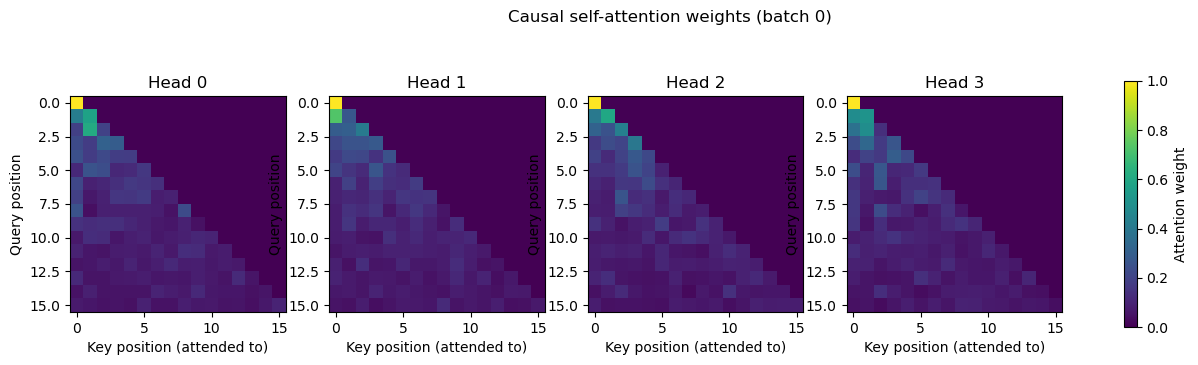

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, n_heads, figsize=(4 * n_heads, 4))
for h, ax in enumerate(axes):
    im = ax.imshow(w[0, h].numpy(), cmap="viridis", vmin=0, vmax=w[0].max().item())
    ax.set_title(f"Head {h}")
    ax.set_xlabel("Key position (attended to)")
    ax.set_ylabel("Query position")
fig.colorbar(im, ax=axes, shrink=0.8, label="Attention weight")
plt.suptitle("Causal self-attention weights (batch 0)")
plt.show()
